# Text Autoencoder: Learning Latent Representations using TF-IDF

## Learning objectives

By completing this notebook, you will be able to:

1. Convert text documents into numerical feature vectors using TF-IDF.
2. Understand why text vectors can be high-dimensional and sparse.
3. Build an encoder–bottleneck–decoder architecture.
4. Train an autoencoder to reconstruct TF-IDF feature vectors.
5. Extract compact latent representations from the encoder.
6. Visualise latent representations in two dimensions.
7. Examine how the latent dimension affects reconstruction quality.
8. Work through a small numerical TF-IDF example and calculate reconstruction loss.
9. Interpret the learned latent representation and identify the limitations of reconstruction-based learning.

> **Important:** This notebook uses a TF-IDF-based dense autoencoder. It reconstructs numerical TF-IDF vectors, not the original sentences word by word. TF-IDF does not preserve word order. This is different from an RNN, which processes a sequence of tokens over time.


## 1. Understanding the task

An autoencoder learns to reproduce its input. It contains three main parts:

- **Encoder:** maps the input vector to a compact representation.
- **Latent space:** stores the compressed representation.
- **Decoder:** attempts to reconstruct the original input vector.

For text, we first represent each document numerically. In this practical, TF-IDF converts a collection of documents into a document–term matrix.

$$
X \in \mathbb{R}^{N \times V}
$$

Here, \(N\) is the number of documents and \(V\) is the vocabulary size. The autoencoder learns a mapping from the original \(V\)-dimensional vector to a smaller latent vector of dimension \(d\), and then reconstructs the \(V\)-dimensional input.

$$
X \rightarrow \text{Encoder} \rightarrow Z \rightarrow \text{Decoder} \rightarrow \hat{X}
$$

The training objective is to minimise reconstruction error between \(X\) and $\hat{X}$.


## 2. Import the required libraries

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 3. Prepare a small text dataset

We will use a small illustrative dataset with four broad themes: **technology, education, healthcare and sports**.

Each document is a short text sample. The category labels are retained only to help us colour the latent-space visualisation. They are **not** provided to the autoencoder during training. This is an unsupervised learning task.


In [73]:
documents = [
    # Technology
    "Artificial intelligence and machine learning are changing modern technology.",
    "Deep learning models can recognise objects in digital images.",
    "Cloud computing provides scalable storage and computing services.",
    "Cybersecurity protects computer networks from malicious attacks.",
    "Data science uses statistics and algorithms to discover useful patterns.",
    "Robotics combines sensors software and intelligent control systems.",
    "Natural language processing helps computers understand human language.",
    "Neural networks learn complex patterns from large datasets.",
    "Artificial intelligence automates repetitive business tasks.",
"Smartphones use advanced processors and operating systems.",
"Computer vision enables machines to analyse visual information.",
"Blockchain technology supports secure digital transactions.",
"Internet of Things connects devices through the internet.",

    # Education
    "Teachers use digital tools to support classroom learning.",
    "Online learning platforms provide access to educational resources.",
    "Students develop programming skills through practical exercises.",
    "Personalised learning adapts educational content to student needs.",
    "Universities offer courses in science technology and engineering.",
    "Educational assessment measures student understanding and progress.",
    "Virtual classrooms support learning from different locations.",
    "Teachers prepare lessons activities and learning materials.",
    "Students collaborate on projects to develop problem solving skills.",
"Online courses allow learners to study at their own pace.",
"Teachers evaluate assignments to measure academic performance.",
"Digital libraries provide access to books and research papers.",
"Educational technology improves student engagement in classrooms.",

    # Healthcare
    "Doctors use medical images to support disease diagnosis.",
    "Healthcare data can help predict patient health risks.",
    "Hospitals use digital systems to manage patient records.",
    "Medical research develops treatments for different diseases.",
    "Wearable devices monitor heart rate and physical activity.",
    "Artificial intelligence can assist clinical decision making.",
    "Patient safety is important in healthcare services.",
    "Public health programmes promote disease prevention.",
    "Doctors monitor blood pressure to assess cardiovascular health.",
"Medical professionals use technology for remote patient monitoring.",
"Vaccination programmes help prevent infectious diseases.",
"Diagnostic laboratories analyse blood and tissue samples.",
"Electronic health records improve patient information management.",

    # Sports
    "Football players practise passing shooting and teamwork.",
    "Cricket teams analyse match statistics and player performance.",
    "Athletes follow training plans to improve physical fitness.",
    "Sports coaches study strategies before important competitions.",
    "Basketball players develop speed coordination and shooting skills.",
    "Fitness tracking devices measure steps and exercise activity.",
    "The team won the tournament after a close final match.",
    "Regular exercise improves strength endurance and health.",
    "Professional athletes follow nutrition plans for better performance.",
"Football coaches analyse player movements during matches.",
"Swimming improves cardiovascular endurance and muscle strength.",
"Sports analytics helps teams evaluate player performance.",
"Athletes practise regularly to improve speed and flexibility.",

  # Environment
"Climate change is affecting ecosystems and weather patterns worldwide.",
"Renewable energy sources help reduce dependence on fossil fuels.",
"Air pollution negatively affects human health and the environment.",
"Deforestation contributes to biodiversity loss and global warming.",
"Solar panels convert sunlight into electricity.",
"Wind turbines generate clean energy from moving air.",
"Recycling helps reduce waste and conserve natural resources.",
"Water conservation is essential for sustainable development.",
"Environmental scientists study the impact of human activities on nature.",
"Plastic pollution threatens marine ecosystems and wildlife.",
"Electric vehicles can help reduce carbon emissions.",
"Forest conservation protects biodiversity and natural habitats.",
"Sustainable agriculture promotes responsible use of soil and water."
]

labels = (
    ["Technology"] * 13 +
    ["Education"] * 13 +
    ["Healthcare"] * 13 +
    ["Sports"] * 13 +
    ["Environment"] * 13
)

data = pd.DataFrame({"text": documents, "category": labels})
data.head(10)

,text,category
0,Artificial intelligence and machine learning a...,Technology
1,Deep learning models can recognise objects in ...,Technology
2,Cloud computing provides scalable storage and ...,Technology
3,Cybersecurity protects computer networks from ...,Technology
4,Data science uses statistics and algorithms to...,Technology
5,Robotics combines sensors software and intelli...,Technology
6,Natural language processing helps computers un...,Technology
7,Neural networks learn complex patterns from la...,Technology
8,Artificial intelligence automates repetitive b...,Technology
9,Smartphones use advanced processors and operat...,Technology


### Observe the dataset

In [74]:
print("Number of documents:", len(data))
print("\nCategory distribution:")
print(data["category"].value_counts())

for category in data["category"].unique():
    print(f"\n{category}:")
    print(data.loc[data.category == category, "text"].iloc[0])

Number of documents: 65

Category distribution:
category
Technology     13
Education      13
Healthcare     13
Sports         13
Environment    13
Name: count, dtype: int64

Technology:
Artificial intelligence and machine learning are changing modern technology.

Education:
Teachers use digital tools to support classroom learning.

Healthcare:
Doctors use medical images to support disease diagnosis.

Sports:
Football players practise passing shooting and teamwork.

Environment:
Climate change is affecting ecosystems and weather patterns worldwide.


## 4. Convert text into TF-IDF vectors

**Term Frequency–Inverse Document Frequency (TF-IDF)** assigns a numerical weight to a term based on its importance in a document relative to the document collection.

- Term Frequency (TF) reflects how frequently a term appears in a document.
- Inverse Document Frequency (IDF) reduces the weight of terms that appear in many documents.

The resulting document–term matrix contains one row per document and one column per vocabulary term. Many entries are zero because a document contains only a small portion of the complete vocabulary.


In [75]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=50,
    ngram_range=(1, 1)
)

X = vectorizer.fit_transform(data["text"]).toarray().astype("float32")
terms = vectorizer.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)
print("Number of documents:", X.shape[0])
print("Vocabulary size:", X.shape[1])
print("Percentage of zero values:", round(100 * np.mean(X == 0), 2), "%")

TF-IDF matrix shape: (65, 50)
Number of documents: 65
Vocabulary size: 50
Percentage of zero values: 95.42 %


In [52]:
print("TF-IDF matrix shape:", X.shape)
print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)
print("Number of input features:", X_train.shape[1])

TF-IDF matrix shape: (32, 50)
Training matrix shape: (24, 50)
Testing matrix shape: (8, 50)
Number of input features: 50


### Inspect the TF-IDF representation

In [76]:
tfidf_df = pd.DataFrame(X, columns=terms)
display(tfidf_df.iloc[:5, :12].round(3))

,analyse,artificial,athletes,coaches,computer,computing,conservation,courses,data,develop,devices,digital
0,0.0,0.537,0.0,0.0,0.000,0.00,0.0,0.0,0.000,0.0,0.0,0.000
1,0.0,0.000,0.0,0.0,0.000,0.00,0.0,0.0,0.000,0.0,0.0,0.738
2,0.0,0.000,0.0,0.0,0.000,0.91,0.0,0.0,0.000,0.0,0.0,0.000
3,0.0,0.000,0.0,0.0,0.707,0.00,0.0,0.0,0.000,0.0,0.0,0.000
4,0.0,0.000,0.0,0.0,0.000,0.00,0.0,0.0,0.509,0.0,0.0,0.000


Each row represents one document and each column represents a vocabulary term. A non-zero value indicates that the term contributes to that document's TF-IDF representation.

### Visualise the sparsity of the matrix


### Worked numerical example: From documents to TF-IDF values

Before using the full dataset, consider three short documents:

- **D1:** `cat sat mat`
- **D2:** `cat ate fish`
- **D3:** `dog ate fish`

The vocabulary is the set of distinct terms: `cat`, `sat`, `mat`, `ate`, `fish`, and `dog`. Each document is represented by a vector with one position for each vocabulary term.

For this example, use the smoothed inverse document frequency convention used by Scikit-learn's default `TfidfVectorizer`:

$$
\operatorname{IDF}(t)=\log\left(\frac{1+N}{1+df(t)}\right)+1
$$

Here, \(N\) is the total number of documents and $$df(t)$$ is the number of documents containing term \(t\). The term-frequency value is based on the term count in the document. Scikit-learn then applies L2 normalisation by default, so each non-zero document vector has unit length.

For `cat`, the term appears in D1 and D2. Therefore, \(N=3\), $$(df(\text{cat})=2) $$, and:

$$
\operatorname{IDF}(\text{cat})=\log(4/3)+1\approx 1.288
$$

For `sat`, which appears only in D1:

$$
\operatorname{IDF}(\text{sat})=\log(4/2)+1\approx 1.693
$$

The IDF of `sat` is higher because it occurs in fewer documents. The next cell calculates the complete TF-IDF matrix so that you can inspect the values and compare them with the manual calculation.

In [77]:
mini_documents = [
    "cat sat mat",
    "cat ate fish",
    "dog ate fish"
]

mini_vectorizer = TfidfVectorizer(norm="l2", smooth_idf=True)
mini_matrix = mini_vectorizer.fit_transform(mini_documents).toarray()
mini_terms = mini_vectorizer.get_feature_names_out()

mini_tfidf_df = pd.DataFrame(
    mini_matrix,
    index=["D1", "D2", "D3"],
    columns=mini_terms
)

print("Vocabulary:", list(mini_terms))
print("IDF values:")
display(pd.DataFrame({"Term": mini_terms, "IDF": mini_vectorizer.idf_}).round(3))
print("L2-normalised TF-IDF matrix:")
display(mini_tfidf_df.round(3))

print("Check the IDF of 'cat':", round(mini_vectorizer.idf_[list(mini_terms).index("cat")], 3))
print("Check the IDF of 'sat':", round(mini_vectorizer.idf_[list(mini_terms).index("sat")], 3))

Vocabulary: ['ate', 'cat', 'dog', 'fish', 'mat', 'sat']
IDF values:


,Term,IDF
0,ate,1.288
1,cat,1.288
2,dog,1.693
3,fish,1.288
4,mat,1.693
5,sat,1.693


L2-normalised TF-IDF matrix:


,ate,cat,dog,fish,mat,sat
D1,0.000,0.474,0.000,0.000,0.623,0.623
D2,0.577,0.577,0.000,0.577,0.000,0.000
D3,0.518,0.000,0.681,0.518,0.000,0.000


Check the IDF of 'cat': 1.288
Check the IDF of 'sat': 1.693


**Reading the result:** Each row is a document and each column is a vocabulary term. A value of zero means that the term does not occur in that document. A larger non-zero value indicates a relatively stronger TF-IDF weight within that document after normalisation.

Notice that the printed TF-IDF values are not simply the IDF values. They combine term frequency and IDF, followed by L2 normalisation. This is why the final values in a row are scaled.

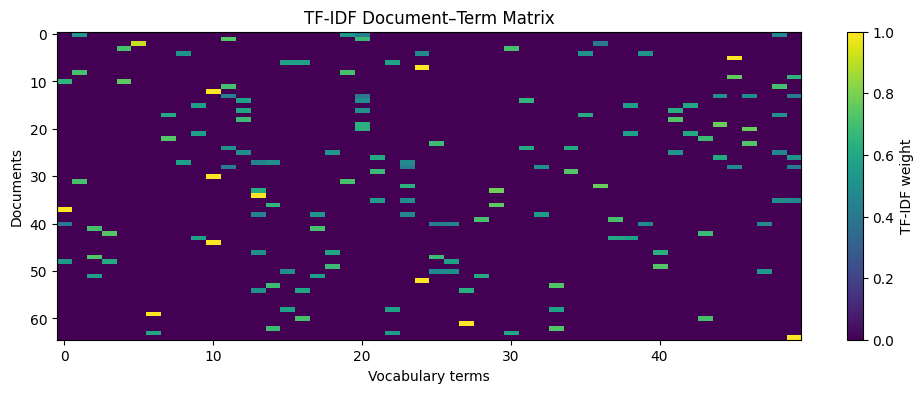

In [78]:
plt.figure(figsize=(12, 4))
plt.imshow(X, aspect="auto", cmap="viridis", interpolation="nearest")
plt.colorbar(label="TF-IDF weight")
plt.xlabel("Vocabulary terms")
plt.ylabel("Documents")
plt.title("TF-IDF Document–Term Matrix")
plt.show()

## 5. Split the data into training and testing sets

We train the autoencoder using the training vectors and evaluate reconstruction on unseen test vectors. Since this is a small dataset, the test set is mainly for demonstrating the workflow.


In [79]:
X_train, X_test = train_test_split(
    X, test_size=0.25, random_state=42
)

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)

Training matrix: (48, 50)
Testing matrix: (17, 50)


## 6. Build the text autoencoder

We will use a dense neural network:

- Input layer: one value for each TF-IDF vocabulary term.
- Encoder layer: reduces the dimensionality.
- Latent layer: creates the compact representation.
- Decoder layer: expands the representation back to the vocabulary dimension.
- Output layer: reconstructs the TF-IDF vector.

The output uses a sigmoid activation so that reconstructed values lie between zero and one, consistent with the range of L2-normalised TF-IDF values.


In [80]:
input_dim = X_train.shape[1]
latent_dim = 4

inputs = keras.Input(shape=(input_dim,), name="tfidf_input")

encoded = layers.Dense(64, activation="relu", name="encoder_hidden")(inputs)
latent = layers.Dense(latent_dim, activation="relu", name="latent_representation")(encoded)

decoded = layers.Dense(64, activation="relu", name="decoder_hidden")(latent)
outputs = layers.Dense(input_dim, activation="sigmoid", name="reconstructed_tfidf")(decoded)

autoencoder = keras.Model(inputs, outputs, name="text_autoencoder")
encoder = keras.Model(inputs, latent, name="text_encoder")

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

autoencoder.summary()

Model: "text_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tfidf_input (InputLayer)        │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 4)              │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_tfidf (Dense)     │ (None, 50)             │         3,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,094 (27.71 KB)

 Trainable params: 7,094 (27.71 KB)

 Non-trainable params: 0 (0.00 B)

### Understand the architecture

The encoder transforms each TF-IDF vector into an 8-dimensional latent vector. The decoder then attempts to reconstruct the original TF-IDF vector.

The latent dimension is a design choice. A smaller latent dimension gives stronger compression, but may lose more information. A larger latent dimension can preserve more information, but provides less compression.


### Mathematical view: How does the autoencoder learn?

Let one TF-IDF document vector be \(x\), containing \(V\) features. The encoder applies a learned weight matrix and bias, followed by an activation function, to produce a latent vector \(z\):

$$
z = f(W_e x + b_e)
$$

The decoder takes this latent vector and attempts to reconstruct the original input:

$$
\hat{x} = g(W_d z + b_d)
$$

Here, $$(W_e)$$ and $$(W_d)$$ are learned weight matrices, $$(b_e)$$ and $$(b_d)$$ are bias vectors, and $$(f)$$ and $$(g)$$ represent activation functions. In this notebook, the hidden layers use ReLU activation and the output layer uses sigmoid activation.

For a batch of documents, the model compares each original TF-IDF value with its reconstructed value. The notebook uses **mean squared error (MSE)** as its reconstruction loss:

$$
\operatorname{MSE}=\frac{1}{B\times V}\sum_{i=1}^{B}\sum_{j=1}^{V}(x_{ij}-\hat{x}_{ij})^2
$$

Here, \(B\) is the number of documents in the batch and (V) is the number of vocabulary features. Training adjusts the network weights to minimise this error. The target supplied during training is the input itself: `autoencoder.fit(X_train, X_train, ...)`.

**Important distinction:** The encoder does not select a few original words and store them directly. It learns numerical combinations of input features. A latent coordinate is therefore not automatically interpretable as a particular word or topic.

### Worked example: Calculate reconstruction loss manually

Suppose a simplified document has only four TF-IDF features. The original vector and the decoder's reconstructed vector are:

$$
x=[0.2,\ 0.8,\ 0.0,\ 0.4]
$$
$$
\hat{x}=[0.1,\ 0.6,\ 0.2,\ 0.5]
$$

The squared errors are:

$$
(0.2-0.1)^2=0.01,\quad (0.8-0.6)^2=0.04
$$
$$
(0.0-0.2)^2=0.04,\quad (0.4-0.5)^2=0.01
$$

Therefore:

$$
\operatorname{MSE}=\frac{0.01+0.04+0.04+0.01}{4}=0.025
$$

The model tries to reduce this average squared difference over all documents and features. This is a small illustrative calculation; the actual notebook computes MSE over the full TF-IDF test matrix.

In [81]:
# Verify the hand-calculated reconstruction MSE
original_example = np.array([0.2, 0.8, 0.0, 0.4])
reconstructed_example = np.array([0.1, 0.6, 0.2, 0.5])

squared_errors = (original_example - reconstructed_example) ** 2
example_mse = np.mean(squared_errors)

print("Original vector:      ", original_example)
print("Reconstructed vector:", reconstructed_example)
print("Squared errors:       ", squared_errors)
print("Mean squared error:   ", round(example_mse, 3))

Original vector:       [0.2 0.8 0.  0.4]
Reconstructed vector: [0.1 0.6 0.2 0.5]
Squared errors:        [0.01 0.04 0.04 0.01]
Mean squared error:    0.025


## 7. Train the autoencoder

In [82]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train, X_train,
    epochs=150,
    batch_size=4,
    shuffle=True,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

print("Training completed.")

Training completed.


### Plot the training and validation loss

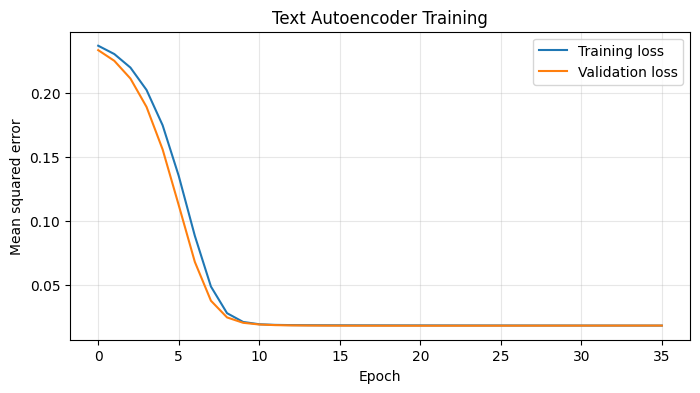

In [83]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Text Autoencoder Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretation:** The loss measures the difference between the original TF-IDF vectors and their reconstructed versions. A decreasing loss indicates that the network is learning to reproduce the input representation. A very small training loss alone does not guarantee that the latent representation is useful for every downstream task.


## 8. Reconstruct the TF-IDF vectors

In [84]:
X_test_reconstructed = autoencoder.predict(X_test, verbose=0)

test_mse = mean_squared_error(
    X_test.flatten(),
    X_test_reconstructed.flatten()
)

print("Test reconstruction MSE:", round(test_mse, 6))
print("Original test shape:", X_test.shape)
print("Reconstructed test shape:", X_test_reconstructed.shape)

Test reconstruction MSE: 0.01882
Original test shape: (17, 50)
Reconstructed test shape: (17, 50)


### Compare original and reconstructed feature values

The decoder produces a reconstructed numerical vector. It does not generate a sentence. We can compare the strongest TF-IDF terms in the original vector with the strongest terms in the reconstructed vector.


In [85]:
test_indices = X_test.shape[0]
sample_position = 0

original_vector = X_test[sample_position]
reconstructed_vector = X_test_reconstructed[sample_position]

top_original = np.argsort(original_vector)[-8:][::-1]
top_reconstructed = np.argsort(reconstructed_vector)[-8:][::-1]

comparison = pd.DataFrame({
    "Original top terms": terms[top_original],
    "Original TF-IDF": original_vector[top_original],
    "Reconstructed top terms": terms[top_reconstructed],
    "Reconstructed TF-IDF": reconstructed_vector[top_reconstructed]
})

display(comparison.round(3))

,Original top terms,Original TF-IDF,Reconstructed top terms,Reconstructed TF-IDF
0,reduce,0.728,data,0.050
1,help,0.685,analyse,0.049
2,technology,0.000,patterns,0.048
3,teams,0.000,artificial,0.047
4,systems,0.000,shooting,0.045
5,teachers,0.000,medical,0.045
6,study,0.000,digital,0.045
7,students,0.000,research,0.044


### Plot original and reconstructed values for the strongest original terms

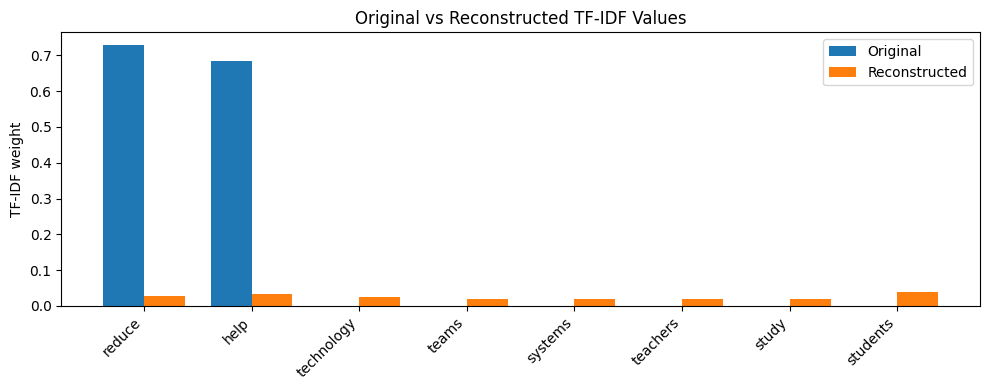

In [86]:
selected_terms = terms[top_original]
original_values = original_vector[top_original]
reconstructed_values = reconstructed_vector[top_original]

x_pos = np.arange(len(selected_terms))
width = 0.38

plt.figure(figsize=(10, 4))
plt.bar(x_pos - width/2, original_values, width, label="Original")
plt.bar(x_pos + width/2, reconstructed_values, width, label="Reconstructed")
plt.xticks(x_pos, selected_terms, rotation=45, ha="right")
plt.ylabel("TF-IDF weight")
plt.title("Original vs Reconstructed TF-IDF Values")
plt.legend()
plt.tight_layout()
plt.show()

**Think about it:** Are the highest-weight terms preserved? Are some terms assigned a non-zero reconstructed value even if they were zero in the original vector? What might this tell us about information loss during compression?


## 9. Extract the latent representations

In [87]:
Z = encoder.predict(X, verbose=0)

print("Original TF-IDF shape:", X.shape)
print("Latent representation shape:", Z.shape)

latent_df = pd.DataFrame(
    Z,
    columns=[f"Latent_{i+1}" for i in range(Z.shape[1])]
)
latent_df["category"] = labels
display(latent_df.head())

Original TF-IDF shape: (65, 50)
Latent representation shape: (65, 4)


,Latent_1,Latent_2,Latent_3,Latent_4,category
0,0.685529,1.601658,1.662769,1.338482,Technology
1,0.698181,1.437840,1.484772,1.128937,Technology
2,0.591707,1.124100,1.629946,1.216166,Technology
3,0.610372,1.441703,1.520078,1.091337,Technology
4,0.583997,1.554144,1.842054,1.278247,Technology


The original TF-IDF matrix has one feature for each vocabulary term. The latent matrix has only eight features per document. These latent values are learned by the encoder during training.

The values do not correspond directly to individual words. Instead, each latent dimension is a learned combination of input features.


### Interpreting the learned latent representation

The latent vector is a compressed numerical description of the original TF-IDF document vector. It is learned because the encoder's weights are adjusted during training to help the decoder reconstruct the input.

Consider what compression means in this practical:

- The input has one coordinate for each term in the vocabulary.
- The latent representation has only a small number of coordinates (eight in the initial model).
- Each latent coordinate can combine information from many TF-IDF input features.
- The decoder uses the compressed values to estimate the original TF-IDF weights.

**What information may be lost?** When many input features are compressed into fewer latent dimensions, the model may not preserve every small TF-IDF value. Some terms may receive lower reconstructed weights, and terms that were originally zero may receive small non-zero reconstructed values. This is an expected possibility in approximate reconstruction.

**Does a low reconstruction error mean that the model understands the meaning of the text?** No. The training objective rewards accurate reconstruction of TF-IDF values. It does not directly reward synonym understanding, sentence meaning, word order, factual reasoning or classification accuracy. Two semantically similar documents may be close in latent space, but this is not guaranteed by the reconstruction objective alone.

**How should you interpret a latent coordinate?** Treat it as a learned feature, not as a named topic or a word, unless a separate analysis provides evidence for that interpretation. The category labels used later are only for visual inspection; they are not used to train the autoencoder.

### Result-analysis activity

After running the model, use the outputs from the reconstruction and latent-space sections to answer:

1. Identify one term whose reconstructed TF-IDF value is close to its original value.
2. Identify one term whose value changes noticeably after reconstruction.
3. Does the model assign non-zero reconstructed values to terms that were absent from the original document?
4. Compare two documents from the same category. Are their latent coordinates close in the plotted projection?
5. Compare documents from different categories. Are any of them close together? Suggest why this might happen.

Support your observations with values from the notebook. Do not conclude that the model has learned semantic categories from the plot alone.

## 10. Visualise the latent space in two dimensions

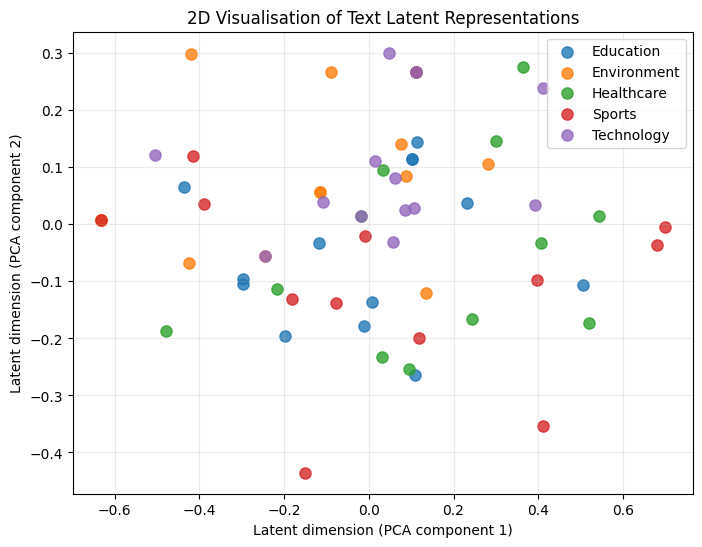

In [88]:
# If the latent dimension is greater than 2, use PCA only for visualisation.
Z_2d = PCA(n_components=2, random_state=42).fit_transform(Z)

plt.figure(figsize=(8, 6))
for category in sorted(data["category"].unique()):
    mask = data["category"].values == category
    plt.scatter(
        Z_2d[mask, 0],
        Z_2d[mask, 1],
        label=category,
        s=65,
        alpha=0.8
    )

plt.xlabel("Latent dimension (PCA component 1)")
plt.ylabel("Latent dimension (PCA component 2)")
plt.title("2D Visualisation of Text Latent Representations")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**How to interpret this plot**

Each point represents one document. Points that are close together have similar coordinates in the projected latent space. The colours indicate the original categories, but the autoencoder was not trained with these labels.

Do not expect perfect category separation. The dataset is small, and the autoencoder was trained only to reconstruct TF-IDF vectors—not to classify documents. PCA is used here to project the learned latent vectors into two dimensions; it is not the autoencoder's latent layer.


## 11. Experiment: What happens when the latent dimension changes?

We will train separate autoencoders using different bottleneck sizes. Compare reconstruction error to understand the effect of compression.

A smaller bottleneck imposes stronger compression. A larger bottleneck gives the network more capacity to retain input information. Reconstruction error is only one measure; it does not by itself measure semantic quality.


In [89]:
def build_and_evaluate_autoencoder(X_train, X_test, latent_dim, epochs=120):
    input_dim = X_train.shape[1]

    inp = keras.Input(shape=(input_dim,))
    x = layers.Dense(64, activation="relu")(inp)
    z = layers.Dense(latent_dim, activation="relu", name="latent")(x)
    x = layers.Dense(64, activation="relu")(z)
    out = layers.Dense(input_dim, activation="sigmoid")(x)

    model = keras.Model(inp, out)
    model.compile(optimizer="adam", loss="mse")

    stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True
    )

    model.fit(
        X_train, X_train,
        epochs=epochs,
        batch_size=4,
        validation_split=0.2,
        callbacks=[stop],
        verbose=0
    )

    prediction = model.predict(X_test, verbose=0)
    mse = mean_squared_error(X_test.flatten(), prediction.flatten())
    return model, mse

latent_dimensions = [2, 4, 8, 16, 24]
results = []

for dim in latent_dimensions:
    model, mse = build_and_evaluate_autoencoder(
        X_train, X_test, latent_dim=dim
    )
    results.append({"Latent dimension": dim, "Test reconstruction MSE": mse})

results_df = pd.DataFrame(results)
display(results_df.round(6))

,Latent dimension,Test reconstruction MSE
0,2,0.018704
1,4,0.018749
2,8,0.018911
3,16,0.018718
4,24,0.018738


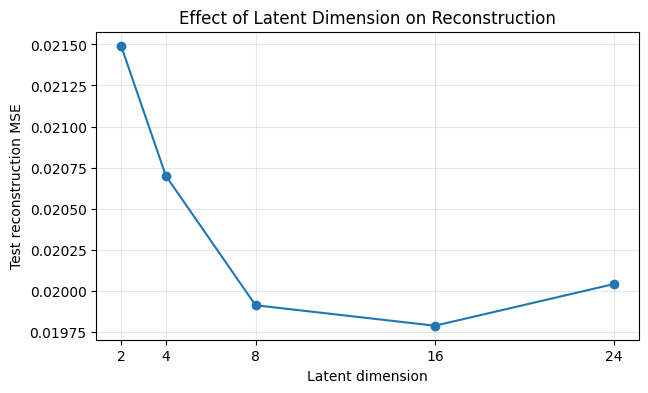

In [49]:
plt.figure(figsize=(7, 4))
plt.plot(
    results_df["Latent dimension"],
    results_df["Test reconstruction MSE"],
    marker="o"
)
plt.xlabel("Latent dimension")
plt.ylabel("Test reconstruction MSE")
plt.title("Effect of Latent Dimension on Reconstruction")
plt.xticks(latent_dimensions)
plt.grid(alpha=0.3)
plt.show()

**Observe and explain:**

- Which latent dimension gives the lowest reconstruction error?
- What happens when the latent dimension is reduced to two?
- Does increasing the latent dimension always guarantee a useful representation?
- What trade-off exists between compression and reconstruction?


## 12.Compare with PCA

PCA is a linear dimensionality-reduction method. An autoencoder can learn nonlinear transformations, depending on its architecture and activation functions. Compare the reconstruction errors of PCA and the autoencoder using the same number of components.

This comparison is illustrative: the models have different assumptions and training procedures.


In [50]:
from sklearn.decomposition import PCA

pca = PCA(n_components=8, random_state=42)
pca.fit(X_train)

X_test_pca_reconstructed = pca.inverse_transform(
    pca.transform(X_test)
)

pca_mse = mean_squared_error(
    X_test.flatten(),
    X_test_pca_reconstructed.flatten()
)

ae_mse = mean_squared_error(
    X_test.flatten(),
    autoencoder.predict(X_test, verbose=0).flatten()
)

print("PCA reconstruction MSE:", round(pca_mse, 6))
print("Autoencoder reconstruction MSE:", round(ae_mse, 6))

PCA reconstruction MSE: 0.016715
Autoencoder reconstruction MSE: 0.02008


## 13. Mandatory to complete: Exercises


### Exercise 1: Change the vocabulary size
Change `max_features` in the `TfidfVectorizer`. Observe how the number of input features and the reconstruction error change.

### Exercise 2: Change the latent dimension
Train the autoencoder with latent dimensions of 2, 4, 8 and 16. Compare reconstruction errors and discuss the compression–reconstruction trade-off.

### Exercise 3: Add more text samples
Add at least five new documents to each category. Retrain the vectorizer and autoencoder. Observe whether the latent-space visualisation changes.

### Exercise 4: Try a new category
Add a fifth category, such as environment or finance. Include several documents and examine the latent-space plot.

### Exercise 5: Interpret reconstruction
For three test documents, compare the top original TF-IDF terms with the top reconstructed terms. Record which terms are preserved and which are lost.

### Exercise 6: Compare PCA and the autoencoder
Compare their reconstruction errors using the same number of latent dimensions. Explain why the results may differ.


# LAB REPORT
## TF-IDF Text Autoencoder: Dimensionality Reduction and Reconstruction

### 1. Introduction

The objective of this practical was to understand how a neural network-based autoencoder can learn compact representations of text data. The experiment used TF-IDF to convert text documents into numerical vectors and a dense autoencoder to compress and reconstruct those vectors.

The practical involved changing vocabulary size, experimenting with latent dimensions, expanding the dataset, introducing a new category, interpreting reconstructed representations, and comparing the autoencoder with Principal Component Analysis (PCA).

### 2. Experimental Setup

**Tools and libraries**
- Python
- Jupyter Notebook
- Pandas and NumPy
- Scikit-learn
- TensorFlow and Keras
- Matplotlib

**Dataset**

The original dataset contained 32 text documents divided equally into four categories:

| Category | Original documents |
|---|---:|
| Technology | 8 |
| Education | 8 |
| Healthcare | 8 |
| Sports | 8 |
| **Total** | **32** |

TF-IDF was used to convert the documents into numerical feature vectors. The autoencoder consisted of an encoder, a latent representation layer, and a decoder.

The model architecture used:
- Input layer: 50 features
- Encoder hidden layer: 64 neurons with ReLU activation
- Latent representation: 8 dimensions by default
- Decoder hidden layer: 64 neurons with ReLU activation
- Output layer: 50 features with sigmoid activation

The model was trained using the Adam optimizer and Mean Squared Error (MSE) loss.

---

### 3. Exercise 1 – Change the Vocabulary Size

**Objective:** Change the `max_features` parameter in the TF-IDF vectorizer and observe its effect on the number of input features and reconstruction error.

**Implementation**

The vocabulary size was changed to:

```python
max_features = 50
```

The TF-IDF vectorizer was rerun, followed by the train-test split and autoencoder construction.

**Observed results**

| Parameter | Result |
|---|---:|
| Number of documents | 32 |
| Vocabulary size | 50 |
| Training matrix | 24 × 50 |
| Testing matrix | 8 × 50 |
| Input features | 50 |
| Test reconstruction MSE | 0.020867 |

The autoencoder architecture was updated to accept 50 input features and reconstruct 50 output features.

**Observation**

Reducing the vocabulary size limits the number of terms represented in the TF-IDF vectors. This reduces the input dimensionality and the amount of information the model must process.

The reconstruction MSE of 0.020867 indicates that the model was able to reconstruct the test TF-IDF representations with a relatively small average squared error.

The training and validation loss curves both decreased and eventually stabilised, with no obvious severe overfitting in the observed plot.

**Conclusion**

The vocabulary size directly determines the dimensionality of the TF-IDF representation and therefore affects the autoencoder's input and output dimensions.

---

### 4. Exercise 2 – Change the Latent Dimension

**Objective:** Experiment with latent dimensions of 2, 4, 8 and 16 to understand the relationship between compression and reconstruction quality.

**Implementation**

The latent dimension was modified in the autoencoder architecture. The following configurations were considered:

- 2 dimensions
- 4 dimensions
- 8 dimensions
- 16 dimensions

**Observed results**

| Latent dimension | Test reconstruction MSE |
|---:|---:|
| 2 | Not recorded |
| 4 | 0.021170 |
| 8 | 0.020867 |
| 16 | Not recorded |

**Observation**

The 4-dimensional model produced a test MSE of 0.021170, while the 8-dimensional model produced a test MSE of 0.020867.

The 8-dimensional representation achieved a slightly lower reconstruction error than the 4-dimensional representation in the recorded experiments.

A smaller latent dimension creates a stronger compression constraint because the model must represent the input using fewer numerical values. A larger latent dimension provides more capacity to preserve information, although it does not guarantee better performance in every experiment.

**Conclusion**

The latent dimension controls the degree of compression performed by the encoder. The recorded results suggest that the 8-dimensional representation reconstructed the test data slightly better than the 4-dimensional representation. The 2- and 16-dimensional configurations require further testing for a complete comparison.

---

### 5. Exercise 3 – Add More Text Samples

**Objective:** Increase the size of the dataset by adding at least five new documents to each existing category, retrain the model, and observe changes in the latent-space visualisation.

**Implementation**

Five additional documents were added to each of the four original categories:

- Technology
- Education
- Healthcare
- Sports

This increased the number of documents in each category from 8 to 13.

The updated dataset contained:

| Category | Documents |
|---|---:|
| Technology | 13 |
| Education | 13 |
| Healthcare | 13 |
| Sports | 13 |
| **Total** | **52** |

The category distribution was verified using the dataset overview.

The TF-IDF vectorizer was then rerun with `max_features=50`.

**Observed TF-IDF results**

| Parameter | Result |
|---|---:|
| Number of documents | 52 |
| Vocabulary size | 50 |
| TF-IDF matrix shape | 52 × 50 |
| Percentage of zero values | 94.69% |
| Training matrix | Expected: 39 × 50 |
| Testing matrix | Expected: 13 × 50 |

**Observation**

Adding more documents increases the amount of text available for learning. It also changes the vocabulary statistics used by TF-IDF, including the inverse document frequency of terms.

The TF-IDF matrix remained sparse, with 94.69% of its values equal to zero. This is expected because individual documents contain only a small portion of the total vocabulary.

**Conclusion**

Increasing the dataset provides the model with more examples from each category. It also changes the TF-IDF representation because the vocabulary statistics are recalculated using the expanded dataset. The final retrained model's reconstruction error and latent-space visualisation were not recorded in the shared results.

---

### 6. Exercise 4 – Try a New Category

**Objective:** Introduce a fifth category and examine how the additional category affects the latent-space representation.

**Implementation**

A new category named **Environment** was selected.

Thirteen documents were prepared covering topics such as:

- Climate change
- Renewable energy
- Air pollution
- Deforestation
- Solar and wind energy
- Recycling
- Water conservation
- Environmental research
- Plastic pollution
- Electric vehicles
- Forest conservation
- Sustainable agriculture

The intended dataset structure became:

| Category | Documents |
|---|---:|
| Technology | 13 |
| Education | 13 |
| Healthcare | 13 |
| Sports | 13 |
| Environment | 13 |
| **Total** | **65** |

The labels were updated to include the fifth category.

**Observation**

Introducing a fifth category increases the diversity of the dataset. The autoencoder is trained to reconstruct the TF-IDF representations of documents from all five categories.

The latent-space visualisation can help examine whether documents belonging to different topics occupy distinguishable regions. However, an autoencoder is trained to reconstruct its input rather than directly classify documents, so clear category separation is not guaranteed.

**Conclusion**

The addition of the Environment category extends the dataset and allows the experiment to examine how a broader range of topics is represented in the latent space. The final five-category training output and visualisation were not recorded in the shared results.

---

### 7. Exercise 5 – Interpret Reconstruction

**Objective:** Compare the original TF-IDF terms with the reconstructed TF-IDF terms for three test documents.

**Methodology**

The trained encoder-decoder model reconstructs the numerical TF-IDF representation of each test document.

For each selected test document, the following comparison is required:

1. Obtain the original TF-IDF vector.
2. Obtain the reconstructed TF-IDF vector.
3. Identify the highest-weighted terms in both vectors.
4. Compare the terms to identify which information was preserved or lost.

**Results**

The three-document term comparison was not completed in the shared results.

The following table can be used to record the observations:

| Test document | Original top terms | Reconstructed top terms | Preserved or lost terms |
|---|---|---|---|
| Document 1 | To be recorded | To be recorded | To be analysed |
| Document 2 | To be recorded | To be recorded | To be analysed |
| Document 3 | To be recorded | To be recorded | To be analysed |

**Expected interpretation**

If important terms appear in both the original and reconstructed representations, it indicates that the autoencoder has retained some of the document's important numerical features.

If certain terms disappear or receive lower weights after reconstruction, it indicates that some information was not fully preserved during compression.

**Conclusion**

This exercise evaluates the quality of reconstruction at the term level rather than relying only on the overall MSE value.

---

### 8. Exercise 6 – Compare PCA and the Autoencoder

**Objective:** Compare the reconstruction errors of PCA and the autoencoder using the same number of latent dimensions.

**Implementation**

Principal Component Analysis (PCA) was used with eight components:

```python
pca = PCA(n_components=8, random_state=42)
pca.fit(X_train)

X_test_pca_reconstructed = pca.inverse_transform(
    pca.transform(X_test)
)
```

The PCA reconstruction error was calculated using Mean Squared Error.

The autoencoder's reconstruction error was also calculated using the same test data.

**Comparison**

| Model | Number of dimensions | Reconstruction MSE |
|---|---:|---:|
| PCA | 8 | Not recorded |
| Autoencoder | 8 | 0.020867* |

*The autoencoder value above is the previously recorded result from the 32-document, 50-feature experiment. A final comparison requires both models to be evaluated on the same updated dataset and test split.*

**Observation**

PCA is a linear dimensionality-reduction technique that identifies directions of maximum variance in the data.

An autoencoder uses a neural network to learn an encoding and decoding process. Depending on its architecture and activation functions, it can learn nonlinear transformations.

The two methods may therefore produce different reconstruction errors because they use different approaches to dimensionality reduction.

**Conclusion**

This comparison demonstrates the difference between a traditional linear dimensionality-reduction method and a neural network-based approach. The final PCA reconstruction error is required to determine which method performed better in this experiment.

---

### 9. Overall Conclusion

This practical demonstrated how text data can be converted into numerical representations using TF-IDF and subsequently compressed and reconstructed using an autoencoder.

The first exercise demonstrated that vocabulary size determines the dimensionality of the input representation. The second exercise showed that the latent dimension influences the compression-reconstruction trade-off, with the recorded 8-dimensional model achieving a slightly lower reconstruction error than the 4-dimensional model.

The dataset was then expanded by adding additional text samples to the original four categories. A fifth category, Environment, was also introduced as an extension of the experiment. These changes provided an opportunity to study how a larger and more diverse dataset affects the numerical representation of text.

The remaining exercises focused on interpreting the reconstructed TF-IDF terms and comparing the autoencoder with PCA. These comparisons are important because reconstruction quality should be assessed not only through numerical error but also through the information retained in the reconstructed representations.

Overall, the experiment provided practical exposure to TF-IDF, neural network architecture, latent representations, dimensionality reduction, model training, reconstruction error, and the limitations of using a small text dataset.

---

### 10. Result Summary

| Exercise | Activity | Recorded outcome |
|---|---|---|
| 1 | Change vocabulary size | 50 features; test MSE 0.020867 |
| 2 | Change latent dimension | 4D MSE 0.021170; 8D MSE 0.020867 |
| 3 | Add more text samples | Dataset expanded from 32 to 52 documents |
| 4 | Add a new category | Environment category prepared; intended total 65 documents |
| 5 | Interpret reconstruction | Term-level comparison pending |
| 6 | Compare PCA and autoencoder | PCA comparison output pending |

**Note:** The report distinguishes between completed experiments with shared outputs and experiments for which final numerical results or visualisations were not provided. The pending results should be added after the corresponding notebook cells are executed.

## 14. Reflection questions

1. Why must text be converted into numerical vectors before it is passed to a dense neural network?
2. What does each dimension of the TF-IDF vector represent?
3. What is the role of the encoder?
4. Why is the bottleneck layer called a latent representation?
5. Does the latent vector store the original words directly?
6. Why does a smaller latent dimension generally increase the compression challenge?
7. How is a text autoencoder different from an RNN?
8. Why does this TF-IDF autoencoder not reconstruct the original sentence word by word?
9. Why might two documents with similar topics have nearby latent representations?
10. What are the limitations of using a small dataset for this experiment?


Q1. Why must text be converted into numerical vectors before it is passed to a dense neural network?

Text must be converted into numerical vectors because dense neural networks perform mathematical computations on numerical values and cannot directly process raw text strings. Techniques such as TF-IDF transform text into numerical representations that can be supplied as input to the network. In this experiment, TF-IDF converts each document into a fixed-length numerical vector, allowing the autoencoder to learn patterns and reconstruct the input representation.


2 Each dimension of a TF-IDF vector represents a unique term in the vocabulary. The value at that dimension indicates the TF-IDF weight of that term in a particular document. Therefore, the vector represents a document numerically based on the importance of its vocabulary terms.


3 The encoder compresses the input TF-IDF vector into a lower-dimensional representation. It learns patterns and important features from the input data and transforms them into a compact latent representation.


4 The bottleneck layer is called a latent representation because it stores a compressed version of the input data in a lower-dimensional space. Its values represent underlying patterns learned by the neural network rather than directly representing the original words or TF-IDF features.


5 No, the latent vector does not store the original words directly. It contains numerical features learned by the encoder that capture underlying patterns in the input TF-IDF representation. These features are used by the decoder to reconstruct an approximation of the original TF-IDF vector.


6 A smaller latent dimension increases the compression challenge because the encoder has fewer numerical values available to represent the original input. It must retain the most useful information while discarding less important details. Excessive compression may result in information loss and higher reconstruction error.


7 A TF-IDF-based text autoencoder converts documents into numerical vectors and learns compressed representations through an encoder and decoder. It does not preserve word order or sequential dependencies. An RNN, on the other hand, processes sequential data and maintains information from previous elements using its hidden state, allowing it to learn sequence-related patterns.


8 The TF-IDF autoencoder does not reconstruct the original sentence word by word because its objective is to reconstruct the numerical TF-IDF representation rather than generate natural-language text. The decoder produces approximate numerical weights corresponding to vocabulary terms, not a sequence of words.


9 Two documents with similar topics may have nearby latent representations because they often contain similar vocabulary and TF-IDF patterns. The encoder learns to compress these patterns into numerical representations, which may result in similar documents being mapped to nearby points in the latent space.


10 Using a small dataset limits the ability of the TF-IDF vectorizer and autoencoder to learn diverse and meaningful patterns. It may result in limited vocabulary, poor generalisation, unstable latent representations and unreliable evaluation results. A larger and more diverse dataset can help the model learn better representations and improve its ability to handle unseen documents.

## 15. Key takeaways

- Text must be represented numerically before it can be processed by a neural network.
- TF-IDF creates a document–term representation based on term importance.
- An autoencoder learns to compress and reconstruct this numerical representation.
- The encoder's output is a compact latent representation.
- The latent dimension controls the degree of compression.
- A two-dimensional plot can help inspect the latent space, but it is only a projection.
- This practical reconstructs TF-IDF vectors; it does not generate natural-language sentences.
- Unlike an RNN, this TF-IDF-based dense autoencoder does not model word order or sequential dependencies.

### Connection to the next topic

Autoencoders demonstrate how neural networks can learn compact representations without class labels. These learned representations are useful in dimensionality reduction, visualisation, anomaly detection and other machine-learning tasks.


## References and further reading
1. Scikit-learn documentation: `TfidfVectorizer`.
2. TensorFlow/Keras documentation: Functional API and model training.


